<a href="https://colab.research.google.com/github/diomani-ouattara/Portfolio-Data-scientist/blob/main/free_shipping_ab_test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Free-shipping threshold A/B test: $75 (control) vs $50 (treatment)

A 4-week randomized experiment on new sessions. Half saw the current $75 free-shipping threshold and half saw a $50 threshold. One row per assigned visitor.

**Decision:** roll $50 out to 100%, keep $75, or do a targeted rollout?

**Short answer: hold.** The $50 threshold lifts conversion by about +1.0 pp (+20%, p < 0.001). It also cuts AOV by 9%, raises our shipping cost per visitor by 20%, and removes most shipping-fee revenue. The only profit-like metric we can compute is not significant, and that metric is biased in favor of the treatment. We need shipping-fee and COGS data to make the call.

**Contents**
1. Setup & data check
2. Randomization: SRM + covariate balance
3. Primary metric: conversion
4. Guardrail: average order value
5. Partial contribution proxy (revenue − shipping cost) + sensitivity
6. Bonus: power & sample size
7. Bonus: segment heterogeneity
8. Recommendation

## 1. Setup & data check

In [23]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
rng = np.random.default_rng(42)
Z = stats.norm.isf(0.025)  # 1.96

# Chart styling: control = blue, treatment = orange; recessive axes and grid
CTRL, TRT, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False, "font.size": 10,
})

In [24]:
# In Colab: run this cell and pick the CSV when the upload button appears.
# Locally: put the CSV next to the notebook (or edit DATA_PATH).
DATA_PATH = "codebaobab-free-shipping-threshold-experiment.csv"
if not os.path.exists(DATA_PATH):
    try:
        from google.colab import files
        uploaded = files.upload()
        DATA_PATH = next(iter(uploaded))
    except ImportError:
        raise FileNotFoundError(f"Put {DATA_PATH} next to this notebook or update DATA_PATH")

df = pd.read_csv(DATA_PATH)
df.head()

,user_id,assigned_group,assignment_date,device_type,returning_customer,converted,items_in_cart,order_value_cents,shipping_cost_cents
0,1,control,2026-06-28,mobile,True,False,NaN,NaN,NaN
1,2,control,2026-06-13,mobile,False,False,NaN,NaN,NaN
2,3,control,2026-06-18,mobile,True,False,NaN,NaN,NaN
3,4,control,2026-06-28,mobile,True,False,NaN,NaN,NaN
4,5,treatment,2026-06-08,mobile,False,False,NaN,NaN,NaN


In [25]:
print(df.shape)
print("user_id unique:", df.user_id.is_unique)
print("\nNulls per column:\n", df.isna().sum())
# Order fields must be null exactly when the visitor did not convert
print("\nconverted vs order_value null:\n", pd.crosstab(df.converted, df.order_value_cents.isna()))
conv_rows = df[df.converted]
print("\nNon-positive values among converters:",
      int((conv_rows[["items_in_cart", "order_value_cents", "shipping_cost_cents"]] <= 0).sum().sum()))

(24000, 9)
user_id unique: True

Nulls per column:
 user_id                    0
assigned_group             0
assignment_date            0
device_type                0
returning_customer         0
converted                  0
items_in_cart          22686
order_value_cents      22686
shipping_cost_cents    22686
dtype: int64

converted vs order_value null:
 order_value_cents  False  True 
converted                      
False                  0  22686
True                1314      0

Non-positive values among converters: 0


In [26]:
# Derived columns (dollars; non-converters = 0 so per-visitor means include them)
df["t"] = (df.assigned_group == "treatment").astype(int)
df["ov"] = df.order_value_cents.fillna(0) / 100        # merchandise revenue
df["sc"] = df.shipping_cost_cents.fillna(0) / 100      # OUR cost to ship
df["proxy"] = df.ov - df.sc                            # partial contribution proxy
df["date"] = pd.to_datetime(df.assignment_date)
df["week"] = (df.date - df.date.min()).dt.days // 7 + 1
T, C = df[df.t == 1], df[df.t == 0]
n1, n0 = len(T), len(C)


def p2(z):
    # Two-sided p-value from a z statistic
    return 2 * stats.norm.sf(abs(z))


def ols_hc1(y, X):
    # OLS with HC1 robust standard errors (intercept added); returns (beta, se)
    X = np.column_stack([np.ones(len(y)), X])
    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    e = y - X @ beta
    n, k = X.shape
    XtXi = np.linalg.inv(X.T @ X)
    V = XtXi @ (X.T * e**2) @ X @ XtXi * n / (n - k)
    return beta, np.sqrt(np.diag(V))


covs = pd.get_dummies(df.device_type, drop_first=True).astype(float)
covs["returning"] = df.returning_customer.astype(float)
covs = pd.concat([covs, pd.get_dummies(df.week, prefix="w", drop_first=True).astype(float)], axis=1)
X_adj = np.column_stack([df.t.values, covs.values])

The data is clean: 24,000 unique visitors, order fields null exactly when `converted = False`, and no zero or negative values.

## 2. Randomization: can we trust the split?

Two checks before looking at any outcome:
- **Sample ratio mismatch (SRM):** did each arm get the share of traffic it was supposed to (50/50)? A mismatch usually means a bug in assignment or logging, and it invalidates the comparison.
- **Covariate balance:** pre-treatment attributes (device, returning customer, assignment date) should look the same in both arms.

Overall: control 12,000  treatment 12,000  ->  SRM chi-square p = 1.000
Per day: treatment share 46.7%-52.4%, joint SRM p = 0.930


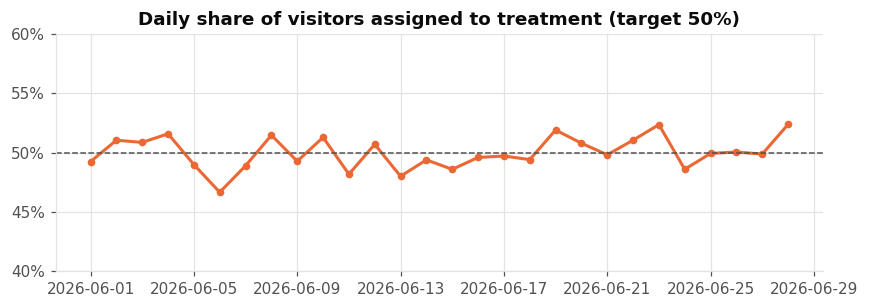

In [27]:
print(f"Overall: control {n0:,}  treatment {n1:,}  ->  SRM chi-square p = {stats.chisquare([n0, n1]).pvalue:.3f}")

daily = pd.crosstab(df.assignment_date, df.assigned_group)
expected = daily.sum(axis=1) / 2
chi_daily = (((daily.treatment - expected) ** 2 / expected) * 2).sum()
share = daily.treatment / daily.sum(axis=1)
print(f"Per day: treatment share {share.min():.1%}-{share.max():.1%}, "
      f"joint SRM p = {stats.chi2.sf(chi_daily, len(daily)):.3f}")

fig, ax = plt.subplots(figsize=(9, 2.8))
ax.plot(pd.to_datetime(share.index), share.values, color=TRT, lw=2, marker="o", ms=4)
ax.axhline(0.5, color=MUTED, lw=1, ls="--")
ax.set_ylim(0.4, 0.6)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Daily share of visitors assigned to treatment (target 50%)")
plt.show()

In [28]:
rows = []
for name, x in [("mobile", df.device_type == "mobile"), ("desktop", df.device_type == "desktop"),
                ("tablet", df.device_type == "tablet"), ("returning customer", df.returning_customer),
                ("assignment day (0-27)", (df.date - df.date.min()).dt.days)]:
    x = x.astype(float)
    a, b = x[df.t == 1], x[df.t == 0]
    rows.append({"covariate": name, "control": b.mean(), "treatment": a.mean(),
                 "SMD": (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)})
balance = pd.DataFrame(rows).set_index("covariate")
display(balance)

for col in ["device_type", "returning_customer", "week"]:
    print(f"{col:20s} chi-square p = {stats.chi2_contingency(pd.crosstab(df[col], df.assigned_group))[1]:.3f}")

,control,treatment,SMD
covariate,,,
mobile,0.4467,0.4562,0.0189
desktop,0.4458,0.4445,-0.0027
tablet,0.1074,0.0993,-0.0266
returning customer,0.2998,0.3048,0.0111
assignment day (0-27),13.4709,13.5659,0.0117


device_type          chi-square p = 0.082
returning_customer   chi-square p = 0.399
week                 chi-square p = 0.714


**Verdict: trustworthy.**
- The split is exactly 12,000 / 12,000 overall, and the daily splits show no mismatch either (p ≈ 0.93).
- Every standardized mean difference (SMD) is below 0.03, far under the usual 0.1 warning level.
- Device has p ≈ 0.08. That's what you'd expect by chance from one of several balance tests. The covariate-adjusted estimates below confirm it doesn't move the result.
- A perfect 50/50 total suggests fixed-allocation randomization, such as shuffling a list, rather than independent coin flips. That's fine.

## 3. Primary metric: conversion

Two-proportion z-test, a 95% Wald CI for the absolute difference, and a log-ratio CI for the relative lift. As a robustness check, a covariate-adjusted linear probability model with robust SEs.

Control   598/12000 = 4.983%
Treatment 716/12000 = 5.967%
Absolute lift  +0.98 pp   95% CI [+0.41, +1.56]   z = 3.35, p = 0.0008
Relative lift  +19.7%    95% CI [+7.7%, +33.1%]
Fisher exact p = 0.0009
Covariate-adjusted lift +0.96 pp (se 0.29), p = 0.0011


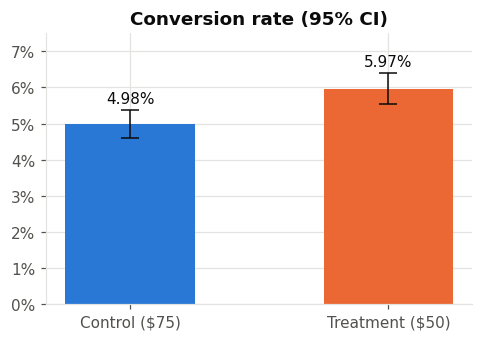

In [29]:
x1, x0 = T.converted.sum(), C.converted.sum()
p1, p0 = x1 / n1, x0 / n0
d = p1 - p0
se = np.sqrt(p1 * (1 - p1) / n1 + p0 * (1 - p0) / n0)
pp = (x1 + x0) / (n1 + n0)
z = d / np.sqrt(pp * (1 - pp) * (1 / n1 + 1 / n0))
lr, se_lr = np.log(p1 / p0), np.sqrt((1 - p1) / x1 + (1 - p0) / x0)
b, s = ols_hc1(df.converted.astype(float).values, X_adj)

print(f"Control   {x0}/{n0} = {p0:.3%}")
print(f"Treatment {x1}/{n1} = {p1:.3%}")
print(f"Absolute lift  {d*100:+.2f} pp   95% CI [{(d-Z*se)*100:+.2f}, {(d+Z*se)*100:+.2f}]   z = {z:.2f}, p = {p2(z):.4f}")
print(f"Relative lift  {p1/p0-1:+.1%}    95% CI [{np.exp(lr-Z*se_lr)-1:+.1%}, {np.exp(lr+Z*se_lr)-1:+.1%}]")
print(f"Fisher exact p = {stats.fisher_exact([[x1, n1-x1], [x0, n0-x0]]).pvalue:.4f}")
print(f"Covariate-adjusted lift {b[1]*100:+.2f} pp (se {s[1]*100:.2f}), p = {p2(b[1]/s[1]):.4f}")

fig, ax = plt.subplots(figsize=(5, 3.2))
rates = [p0, p1]
errs = [Z * np.sqrt(p * (1 - p) / n) for p, n in [(p0, n0), (p1, n1)]]
ax.bar(["Control ($75)", "Treatment ($50)"], rates, color=[CTRL, TRT], width=0.5, yerr=errs,
       capsize=6, error_kw={"ecolor": INK, "lw": 1})
for i, r in enumerate(rates):
    ax.text(i, r + errs[i] + 0.002, f"{r:.2%}", ha="center", color=INK)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_ylim(0, 0.075)
ax.set_title("Conversion rate (95% CI)")
plt.show()

**Result:** conversion rose from **4.98% to 5.97%**, a lift of **+0.98 pp, 95% CI [+0.41, +1.56], p ≈ 0.0008**. That's **+19.7% relative (CI +7.7% to +33%)**. Adjusting for covariates gives the same answer (+0.96 pp). The lift is very unlikely to be zero, but its size is uncertain: the true lift could be anywhere from about +8% to +33%.

## 4. Guardrail: average order value (AOV)

Note: AOV among converters is **not** a randomized comparison. The treatment arm contains extra, different buyers. So we also look at orders **per assigned visitor** by basket size, which is randomized.

In [30]:
a1, a0 = T[T.converted].ov, C[C.converted].ov
w = stats.ttest_ind(a1, a0, equal_var=False)
ci = w.confidence_interval()
boot = [rng.choice(a1.values, len(a1)).mean() - rng.choice(a0.values, len(a0)).mean() for _ in range(10000)]

print(f"AOV control ${a0.mean():.2f}   treatment ${a1.mean():.2f}   diff {a1.mean()-a0.mean():+.2f} ({a1.mean()/a0.mean()-1:+.1%})")
print(f"Welch 95% CI [{ci.low:+.2f}, {ci.high:+.2f}], p = {w.pvalue:.5f};  bootstrap CI {np.percentile(boot, [2.5, 97.5]).round(2)}")
print(f"Median ${a0.median():.2f} -> ${a1.median():.2f};  Mann-Whitney p = {stats.mannwhitneyu(a1, a0).pvalue:.5f}")
print(f"Items/order {C[C.converted].items_in_cart.mean():.2f} -> {T[T.converted].items_in_cart.mean():.2f};  "
      f"our ship cost/order ${C[C.converted].sc.mean():.2f} -> ${T[T.converted].sc.mean():.2f}")
print(f"Implied value of the INCREMENTAL orders: ${(T.ov.mean()-C.ov.mean())/d:.0f} per added order")

AOV control $92.63   treatment $84.10   diff -8.52 (-9.2%)
Welch 95% CI [-12.57, -4.47], p = 0.00004;  bootstrap CI [-12.62  -4.48]
Median $85.97 -> $78.50;  Mann-Whitney p = 0.00025
Items/order 2.60 -> 2.59;  our ship cost/order $7.12 -> $7.12
Implied value of the INCREMENTAL orders: $41 per added order


,control /100 visitors,treatment /100 visitors,diff,CI low,CI high,p
basket,,,,,,
< $50,0.5000,0.8333,0.3333,0.1275,0.5392,0.0015
$50-75,1.4333,1.7750,0.3417,0.0238,0.6595,0.0351
>= $75,3.0500,3.3583,0.3083,-0.1373,0.7539,0.1750


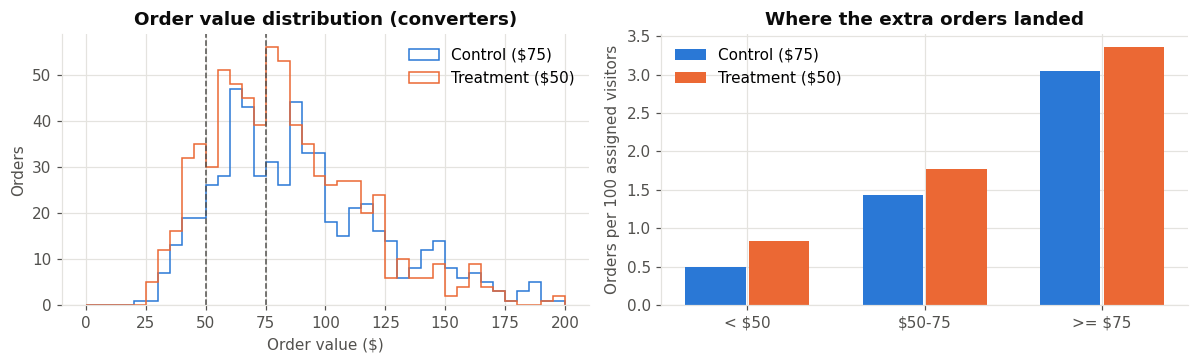

In [31]:
conv = df[df.converted].copy()
conv["band"] = pd.cut(conv.ov, [0, 50, 75, np.inf], labels=["< $50", "$50-75", ">= $75"], right=False)
bt = pd.crosstab(conv.band, conv.assigned_group)
rows = []
for band in bt.index:
    r1, r0 = bt.loc[band, "treatment"] / n1, bt.loc[band, "control"] / n0
    se_b = np.sqrt(r1 * (1 - r1) / n1 + r0 * (1 - r0) / n0)
    rows.append({"basket": band, "control /100 visitors": r0 * 100, "treatment /100 visitors": r1 * 100,
                 "diff": (r1 - r0) * 100, "CI low": (r1 - r0 - Z * se_b) * 100,
                 "CI high": (r1 - r0 + Z * se_b) * 100, "p": p2((r1 - r0) / se_b)})
bands = pd.DataFrame(rows).set_index("basket")
display(bands)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
bins = np.arange(0, 205, 5)
for g, col, lab in [(C, CTRL, "Control ($75)"), (T, TRT, "Treatment ($50)")]:
    axes[0].hist(g[g.converted].ov, bins=bins, histtype="step", lw=2, color=col, label=lab)
for thr in (50, 75):
    axes[0].axvline(thr, color=MUTED, ls="--", lw=1)
axes[0].set_xlabel("Order value ($)"); axes[0].set_ylabel("Orders")
axes[0].set_title("Order value distribution (converters)"); axes[0].legend()

xpos = np.arange(len(bands))
axes[1].bar(xpos - 0.18, bands["control /100 visitors"], 0.34, color=CTRL, label="Control ($75)")
axes[1].bar(xpos + 0.18, bands["treatment /100 visitors"], 0.34, color=TRT, label="Treatment ($50)")
axes[1].set_xticks(xpos, bands.index)
axes[1].set_ylabel("Orders per 100 assigned visitors")
axes[1].set_title("Where the extra orders landed"); axes[1].legend()
plt.tight_layout(); plt.show()

**Result: AOV fell sharply, and it changes the picture.**
- **AOV dropped from $92.63 to $84.10 (−9.2%), CI [−$12.57, −$4.47], p < 0.001.** The median dropped too.
- **The drop comes from mix, not trade-down.** Orders of $75 or more did *not* fall per visitor. The extra orders are small, averaging about **$41**. Each one still costs us the same ~$7.12 to ship, on about half the merchandise.
- **The lift isn't where the hypothesis predicted.** If carts were stalling just under $75, new orders should land in the $50–75 band. Instead, orders under $50 rose just as much, even though their shipping terms didn't change. That points to a general "free shipping feels reachable" messaging effect.

## 5. Partial contribution proxy: merchandise revenue − our shipping cost, per assigned visitor

Non-converters count as $0. This is **not** profit: customer-paid shipping fees and product cost are absent.

In [32]:
def per_visitor(col, label):
    y1, y0 = T[col].values, C[col].values
    dd = y1.mean() - y0.mean()
    se_ = np.sqrt(y1.var(ddof=1) / n1 + y0.var(ddof=1) / n0)
    bs = np.array([rng.choice(y1, n1).mean() - rng.choice(y0, n0).mean() for _ in range(3000)])
    lo, hi = np.percentile(bs, [2.5, 97.5])
    return {"metric": label, "control $": y0.mean(), "treatment $": y1.mean(), "diff $": dd,
            "rel": dd / y0.mean(), "CI low": dd - Z * se_, "CI high": dd + Z * se_, "p": p2(dd / se_),
            "boot low": lo, "boot high": hi}

pv = pd.DataFrame([per_visitor("ov", "merchandise revenue"), per_visitor("sc", "our shipping cost"),
                   per_visitor("proxy", "revenue - shipping cost")]).set_index("metric")
display(pv)
b, s = ols_hc1(df.proxy.values, X_adj)
print(f"Covariate-adjusted proxy diff {b[1]:+.3f} $/visitor (se {s[1]:.3f}), p = {p2(b[1]/s[1]):.3f}")

,control $,treatment $,diff $,rel,CI low,CI high,p,boot low,boot high
metric,,,,,,,,,
merchandise revenue,4.6159,5.0182,0.4023,0.0872,-0.1495,0.9541,0.1530,-0.1659,0.9622
our shipping cost,0.3548,0.4245,0.0698,0.1967,0.0278,0.1118,0.0011,0.0271,0.1089
revenue - shipping cost,4.2611,4.5936,0.3325,0.0780,-0.1820,0.8471,0.2053,-0.1964,0.8613


Covariate-adjusted proxy diff +0.317 $/visitor (se 0.263), p = 0.228


**What the proxy shows:** treatment comes out **+$0.33 per visitor (+7.8%), CI [−$0.18, +$0.85], p ≈ 0.21**. That's not significant. The extra shipping cost is certain (+20%, p ≈ 0.001). The extra merchandise revenue is not distinguishable from zero.

**The proxy is biased in treatment's favor**, for two reasons:
1. **It counts revenue as if it were margin.** Treatment's gain is all revenue, and real contribution keeps only the gross-margin share of it. The extra shipping cost is paid in full.
2. **It ignores lost shipping fees.** Orders below the threshold pay a flat fee. Control charges it under $75 and treatment only under $50, so treatment gives up most of that fee revenue.

The next cell puts numbers on both, using **assumed** values for gross margin and the fee. Neither is in the data.

Fee-paying orders: control 232 (38.8% of orders), treatment 100 (14.0%)
fee $0.00: break-even gross margin = 17%
fee $5.99: break-even gross margin = 34%
fee $7.99: break-even gross margin = 39%
fee $9.99: break-even gross margin = 45%


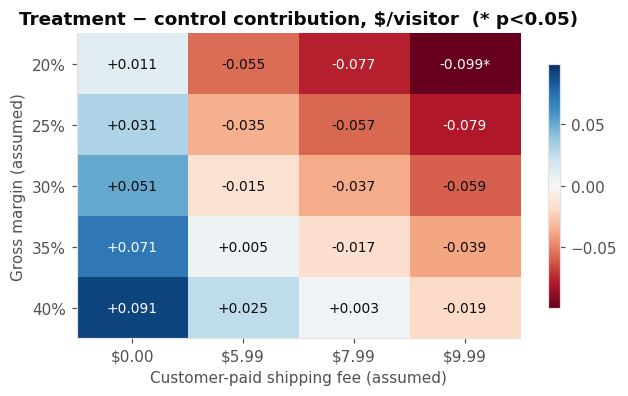

In [33]:
paid_ctrl = (C.converted & (C.ov < 75)).sum()
paid_trt = (T.converted & (T.ov < 50)).sum()
print(f"Fee-paying orders: control {paid_ctrl} ({paid_ctrl/x0:.1%} of orders), treatment {paid_trt} ({paid_trt/x1:.1%})")


def contrib(frame, threshold, margin, fee):
    # contribution/visitor = margin * merchandise - our ship cost + fee if order below threshold
    paid = (frame.converted & (frame.ov < threshold)).astype(float)
    return margin * frame.ov - frame.sc + fee * paid


margins, fees = [0.20, 0.25, 0.30, 0.35, 0.40], [0, 5.99, 7.99, 9.99]
grid, pgrid = pd.DataFrame(index=margins, columns=fees, dtype=float), pd.DataFrame(index=margins, columns=fees, dtype=float)
for m in margins:
    for f in fees:
        y1, y0 = contrib(T, 50, m, f).values, contrib(C, 75, m, f).values
        dd = y1.mean() - y0.mean()
        grid.loc[m, f] = dd
        pgrid.loc[m, f] = p2(dd / np.sqrt(y1.var(ddof=1) / n1 + y0.var(ddof=1) / n0))

dOV, dSC = T.ov.mean() - C.ov.mean(), T.sc.mean() - C.sc.mean()
dPaid = paid_trt / n1 - paid_ctrl / n0
for f in fees:
    print(f"fee ${f:.2f}: break-even gross margin = {(dSC - f * dPaid) / dOV:.0%}")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
lim = np.abs(grid.values).max()
im = ax.imshow(grid.values, cmap="RdBu", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(len(fees)), [f"${f:.2f}" for f in fees])
ax.set_yticks(range(len(margins)), [f"{m:.0%}" for m in margins])
ax.set_xlabel("Customer-paid shipping fee (assumed)"); ax.set_ylabel("Gross margin (assumed)")
ax.grid(False)
for i in range(len(margins)):
    for j in range(len(fees)):
        star = "*" if pgrid.values[i, j] < 0.05 else ""
        v = grid.values[i, j]
        ax.text(j, i, f"{v:+.3f}{star}", ha="center", va="center", fontsize=9,
                color="white" if abs(v) > 0.6 * lim else INK)
ax.set_title("Treatment − control contribution, $/visitor  (* p<0.05)")
plt.colorbar(im, ax=ax, shrink=0.8)
plt.show()

**Takeaway:**
- **Break-even needs a gross margin of about 34% at a $5.99 fee, 39% at $7.99 and 45% at $9.99.** For a blended electronics/grocery/home catalog that's a high bar, but our real margins have to replace this assumption.
- At 20–30% margins and $6–10 fees the point estimate is **negative**. At 20% margin with a $9.99 fee it's significantly negative.
- **Scale, per 1M assigned visitors:** about +9,800 orders and +$402K merchandise. Against that: +$70K shipping cost, and about 11,000 fewer fee-paying orders (about −$88K at $7.99). Product cost on the $402K still has to come out.

**Records needed for a rollout decision:**
- Customer-paid shipping fee per order.
- COGS per order, or gross margin by category.
- Returns and refunds.
- Payment and fulfilment cost.
- Carrier-rate effects at rollout volume.
- 30/60/90-day repeat purchase for buyers acquired by treatment.
- Interaction with any paid free-shipping membership.

## 6. Bonus: was the sample big enough?

MDE at 80% power (alpha .05, 12,000/arm, baseline 4.98%): 0.79 pp (16% relative)



,true lift (pp),relative,power at n=12k/arm,n/arm for 80% power
0,0.9833,0.1973,0.9176,8401
1,0.7500,0.1505,0.7324,14151
2,0.5000,0.1003,0.4126,31140
3,0.2500,0.0502,0.1400,121748
4,0.1000,0.0201,0.0542,750350


Contribution metric (30% margin, $7.99 fee, sd $5.35): detect $0.10/visitor -> 45,006 visitors/arm
Contribution metric (30% margin, $7.99 fee, sd $5.35): detect $0.05/visitor -> 180,023 visitors/arm
Contribution metric (30% margin, $7.99 fee, sd $5.35): detect $0.03/visitor -> 500,065 visitors/arm


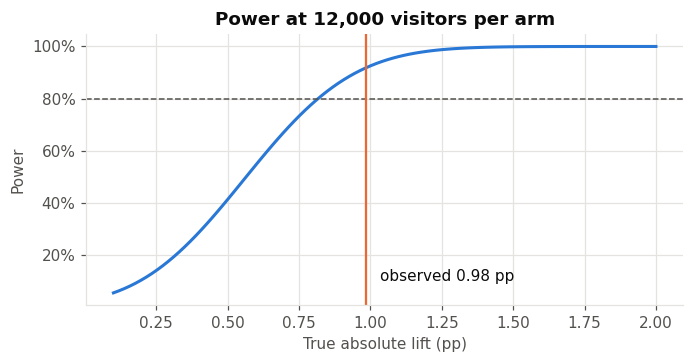

In [34]:
def n_needed(base, delta, power=0.8):
    q = base + delta
    zb = stats.norm.isf(1 - power)
    return ((Z * np.sqrt(2 * ((base + q) / 2) * (1 - (base + q) / 2))
             + zb * np.sqrt(base * (1 - base) + q * (1 - q))) / delta) ** 2


def power_at(base, delta, n):
    return stats.norm.sf(Z - delta / np.sqrt(base * (1 - base) / n + (base + delta) * (1 - base - delta) / n))


mde = (Z + stats.norm.isf(0.2)) * np.sqrt(2 * p0 * (1 - p0) / n0)
print(f"MDE at 80% power (alpha .05, {n0:,}/arm, baseline {p0:.2%}): {mde*100:.2f} pp ({mde/p0:.0%} relative)\n")
display(pd.DataFrame([{"true lift (pp)": dl * 100, "relative": dl / p0, "power at n=12k/arm": power_at(p0, dl, n0),
                       "n/arm for 80% power": round(n_needed(p0, dl))} for dl in [d, 0.0075, 0.005, 0.0025, 0.001]]))

y_c = np.concatenate([contrib(T, 50, 0.30, 7.99), contrib(C, 75, 0.30, 7.99)])
sd_c = y_c.std()
for delta in [0.10, 0.05, 0.03]:
    print(f"Contribution metric (30% margin, $7.99 fee, sd ${sd_c:.2f}): detect ${delta:.2f}/visitor "
          f"-> {2 * ((Z + stats.norm.isf(0.2)) * sd_c / delta) ** 2:,.0f} visitors/arm")

lifts = np.linspace(0.001, 0.02, 100)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(lifts * 100, power_at(p0, lifts, n0), color=CTRL, lw=2)
ax.axhline(0.8, color=MUTED, ls="--", lw=1)
ax.axvline(d * 100, color=TRT, lw=1.5)
ax.text(d * 100 + 0.05, 0.1, f"observed {d*100:.2f} pp", color=INK)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel("True absolute lift (pp)"); ax.set_ylabel("Power")
ax.set_title("Power at 12,000 visitors per arm")
plt.show()

- **For conversion, yes.** The test could reliably detect a lift of 0.79 pp or more, and it had about 92% power for the effect it found.
- **For a smaller true effect, no.** A 0.5 pp lift (10%) would have had only about 41% power and needs about 31K per arm. A 0.25 pp lift needs about 122K per arm.
- **For the money metric, far from enough.** Detecting a $0.05-per-visitor contribution difference needs about 180K visitors per arm. At this platform's traffic that's still cheap to run.

## 7. Bonus: does the effect hold across segments?

In [35]:
rows = []
def seg(mask, label):
    s_ = df[mask]
    t, c = s_[s_.t == 1], s_[s_.t == 0]
    q1, q0 = t.converted.mean(), c.converted.mean()
    se_ = np.sqrt(q1 * (1 - q1) / len(t) + q0 * (1 - q0) / len(c))
    pd_ = t.proxy.mean() - c.proxy.mean()
    sep = np.sqrt(t.proxy.var() / len(t) + c.proxy.var() / len(c))
    rows.append({"segment": label, "n ctrl": len(c), "n trt": len(t), "conv ctrl": q0, "conv trt": q1,
                 "lift pp": (q1 - q0) * 100, "se pp": se_ * 100, "p": p2((q1 - q0) / se_),
                 "AOV ctrl": c[c.converted].ov.mean(), "AOV trt": t[t.converted].ov.mean(),
                 "proxy diff $": pd_, "proxy se": sep})

for dv in ["desktop", "mobile", "tablet"]:
    seg(df.device_type == dv, dv)
seg(~df.returning_customer, "new")
seg(df.returning_customer, "returning")
for dv in ["desktop", "mobile", "tablet"]:
    for r, lab in [(False, "new"), (True, "returning")]:
        seg((df.device_type == dv) & (df.returning_customer == r), f"{dv} / {lab}")
for wk in range(1, 5):
    seg(df.week == wk, f"week {wk}")
segs = pd.DataFrame(rows).set_index("segment")
display(segs)


def heterogeneity(keys, eff_col, se_col):
    # Cochran's Q: are the subgroup effects more different than chance allows?
    eff, ses = segs.loc[keys, eff_col].values, segs.loc[keys, se_col].values
    w_ = 1 / ses**2
    Q = (w_ * (eff - (w_ * eff).sum() / w_.sum()) ** 2).sum()
    return stats.chi2.sf(Q, len(keys) - 1)

devices, cust, weeks = ["desktop", "mobile", "tablet"], ["new", "returning"], [f"week {w}" for w in range(1, 5)]
print(f"Heterogeneity p-values: conversion x device {heterogeneity(devices, 'lift pp', 'se pp'):.2f}, "
      f"x new/returning {heterogeneity(cust, 'lift pp', 'se pp'):.2f}, x week {heterogeneity(weeks, 'lift pp', 'se pp'):.2f}; "
      f"proxy x device {heterogeneity(devices, 'proxy diff $', 'proxy se'):.2f}, "
      f"x new/returning {heterogeneity(cust, 'proxy diff $', 'proxy se'):.2f}")

,n ctrl,n trt,conv ctrl,conv trt,lift pp,se pp,p,AOV ctrl,AOV trt,proxy diff $,proxy se
segment,,,,,,,,,,,
desktop,5350,5334,0.0521,0.0607,0.8593,0.4465,0.0543,92.5776,82.4098,0.1133,0.3931
mobile,5361,5474,0.0502,0.0617,1.1569,0.4413,0.0087,91.7510,84.6552,0.5418,0.3962
tablet,1289,1192,0.0388,0.0453,0.6512,0.8075,0.4200,97.6050,90.8146,0.2952,0.7680
new,8403,8342,0.0440,0.0531,0.9073,0.3322,0.0063,92.6888,85.6731,0.3999,0.2994
returning,3597,3658,0.0634,0.0746,1.1245,0.5948,0.0587,92.5244,81.5570,0.1515,0.5256
desktop / new,3769,3672,0.0448,0.0536,0.8810,0.5019,0.0792,94.1363,82.3183,0.1299,0.4443
desktop / returning,1581,1662,0.0696,0.0764,0.6838,0.9133,0.4540,90.1828,82.5517,-0.0198,0.7987
mobile / new,3721,3829,0.0457,0.0562,1.0464,0.5056,0.0385,89.4231,87.5481,0.7522,0.4545
mobile / returning,1640,1645,0.0604,0.0748,1.4406,0.8755,0.0999,95.7485,79.5985,0.0806,0.7831


Heterogeneity p-values: conversion x device 0.82, x new/returning 0.75, x week 0.44; proxy x device 0.74, x new/returning 0.68


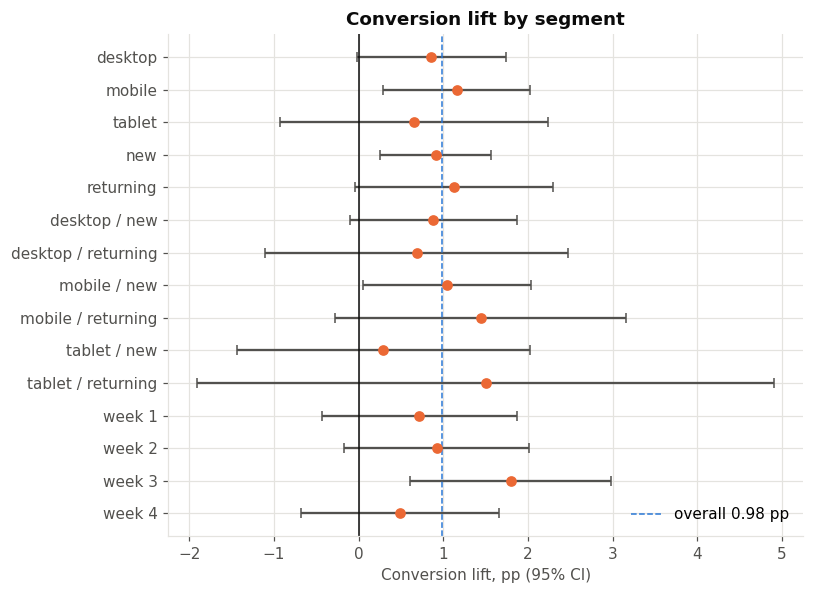

In [36]:
order = ["desktop", "mobile", "tablet", "new", "returning"] + [i for i in segs.index if "/" in i] + weeks
plot = segs.loc[order[::-1]]
fig, ax = plt.subplots(figsize=(7.5, 5.5))
yy = np.arange(len(plot))
ax.errorbar(plot["lift pp"], yy, xerr=Z * plot["se pp"], fmt="o", color=TRT, ecolor=MUTED, ms=6, capsize=3)
ax.axvline(0, color=INK, lw=1)
ax.axvline(d * 100, color=CTRL, ls="--", lw=1, label=f"overall {d*100:.2f} pp")
ax.set_yticks(yy, plot.index)
ax.set_xlabel("Conversion lift, pp (95% CI)")
ax.set_title("Conversion lift by segment")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

**The lift is broad, not concentrated.**
- Every point estimate is positive, and every CI overlaps the overall effect.
- Heterogeneity tests are all non-significant: device p ≈ 0.82, new vs returning p ≈ 0.75, week p ≈ 0.44, and the proxy splits likewise.
- Mobile and new users reach significance because those groups are bigger, not because their effect is larger. Choosing a segment after looking at 11+ cuts would be fitting noise.
- **No case for a segment-specific rollout.** Any segment strategy should be pre-registered and tested on its own.

## 8. Recommendation to the VP of Growth

**Hold. Keep the $75 threshold for now. This is a "gather more evidence" decision, not a "no".**

| Question | Answer |
|---|---|
| Randomization trustworthy? | Yes: no SRM, covariates balanced |
| Conversion lift? | **+0.98 pp (+20%), 95% CI [+0.41, +1.56], p < 0.001** |
| AOV guardrail | **−$8.52 (−9.2%), p < 0.001**: more small orders, each costing the full shipping cost |
| Revenue − shipping cost per visitor | +$0.33, CI [−$0.18, +$0.85], **not significant**, and biased upward |
| Full economics | Break-even needs a 34–45% gross margin at a $6–10 fee; likely negative at typical margins |
| Segment rollout? | No: no evidence the effect differs by segment |

**Next steps**
1. **Days, no new test:** join customer-paid shipping fees and COGS onto these 1,314 orders and recompute contribution per visitor. Clearly positive → ship. Clearly negative → keep $75.
2. **If still inconclusive:** run a follow-up with **contribution per visitor as the primary metric** and about 200K+ visitors per arm. Add a **$60–65 arm**, and run long enough to measure repeat purchase from newly acquired customers.

**Assumptions:**
- Our shipping cost doesn't depend on who pays for shipping.
- The 4-week window captures the main effect, with no strong novelty decay. The week-by-week lift was stable.
- The margin and fee values in the sensitivity analysis are placeholders.